# yfinance-Rundgang am Beispiel Microsoft (MSFT)

Dieses Notebook ruft **alle Basisfunktionen** der `yfinance`-Schnittstelle einmal für Microsoft auf und
protokolliert je Aufruf: Status (`ok` / `leer` / `fehler`), Größe des Ergebnisses und Antwortzeit.
Es enthält keine Portfoliodaten.

Gelesen wird ausschließlich (keine Konten, keine Zugangsdaten). yfinance ist ein **inoffizieller** Zugang zu
Yahoo Finance: Umfang und Drosselung können sich ohne Ankündigung ändern.

In [1]:
import time, warnings
from importlib import metadata
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 40)

SYMBOL = "MSFT"
t = yf.Ticker(SYMBOL)
print("yfinance", metadata.version("yfinance"), "| pandas", pd.__version__, "| Abruf", pd.Timestamp.now("UTC").strftime("%Y-%m-%d %H:%M UTC"))

LOG = []
def run(area, name, fn, show=True, rows=5):
    """Funktion ausführen, Status/Größe/Dauer protokollieren, Vorschau zeigen."""
    start = time.perf_counter()
    try:
        res, err = fn(), None
    except Exception as exc:
        res, err = None, type(exc).__name__
    sec = round(time.perf_counter() - start, 2)
    try:
        n = 0 if res is None else len(res) if hasattr(res, "__len__") and not isinstance(res, str) else 1
    except Exception:
        n = 1
    if isinstance(res, str) and res in ("", "-"):
        n = 0
    status = "fehler" if err else ("leer" if n == 0 else "ok")
    LOG.append(dict(Bereich=area, Funktion=name, Status=status, Größe=n, Sekunden=sec, Fehler=err or ""))
    print(f"[{status:6}] {name:38} Größe={n:<6} {sec:>5.2f}s {err or ''}")
    if show and res is not None and n:
        if isinstance(res, pd.DataFrame): display(res.head(rows))
        elif isinstance(res, pd.Series): display(res.head(rows))
        elif isinstance(res, dict): display(pd.Series(res).head(rows))
        elif isinstance(res, list): display(res[:rows])
        else: print(res)
    return res

yfinance 1.7.0 | pandas 3.1.0 | Abruf 2026-10-31 15:30 UTC


## 1. Identität und Stammdaten

In [2]:
fast = run("Stammdaten", "fast_info", lambda: {k: t.fast_info[k] for k in
    ("lastPrice", "previousClose", "currency", "exchange", "marketCap", "lastVolume", "fiftyDayAverage", "yearHigh", "yearLow")}, rows=9)
info = run("Stammdaten", "info", lambda: dict(t.info), show=False)
print(len(info), "Felder in info; Auswahl:")
display(pd.Series({k: info.get(k) for k in ["longName", "quoteType", "exchange", "currency", "sector", "industry", "country",
    "marketCap", "sharesOutstanding", "trailingPE", "forwardPE", "priceToBook", "dividendYield", "beta", "recommendationMean", "numberOfAnalystOpinions"]}))
run("Stammdaten", "get_isin", lambda: t.get_isin())
run("Stammdaten", "history_metadata", lambda: t.history_metadata, rows=8)

[ok    ] fast_info                              Größe=9       0.89s 


lastPrice                    521.909973
previousClose                  529.0521
currency                            USD
exchange                            NMS
marketCap          3875804999200.384277
lastVolume                     35618300
fiftyDayAverage              512.910601
yearHigh                     551.150024
yearLow                      349.200012
dtype: object

[ok    ] info                                   Größe=187     0.48s 
187 Felder in info; Auswahl:


longName                       Microsoft Corporation
quoteType                                     EQUITY
exchange                                         NMS
currency                                         USD
sector                                    Technology
industry                   Software - Infrastructure
country                                United States
marketCap                              3875804807168
sharesOutstanding                         7426194552
trailingPE                                 27.239561
forwardPE                                  21.618698
priceToBook                                 8.238385
dividendYield                                   0.75
beta                                           1.099
recommendationMean                           1.39286
numberOfAnalystOpinions                           51
dtype: object

[leer  ] get_isin                               Größe=0       1.09s 
[ok    ] history_metadata                       Größe=34      0.00s 
{'YF repair?': False,
 'chartPreviousClose': 524.51,
 'currency': 'USD',
 'currentTradingPeriod': {'post': {'end': Timestamp('2026-10-30 20:00:00-0400', tz='America/New_York'),
                                   'start': Timestamp('2026-10-30 16:00:00-0400', tz='America/New_York')},
                          'pre': {'end': Timestamp('2026-10-30 09:30:00-0400', tz='America/New_York'),
                                  'start': Timestamp('2026-10-30 04:00:00-0400', tz='America/New_York')},
                          'regular': {'end': Timestamp('2026-10-30 16:00:00-0400', tz='America/New_York'),
                                      'start': Timestamp('2026-10-30 09:30:00-0400', tz='America/New_York')}},
 'dataGranularity': '1h',
 'exchangeName': 'NMS',
 'exchangeTimezoneName': 'America/New_York',
 'fiftyTwoWeekHigh': 551.15,
 'fiftyTwoWeekLow': 349.2,


{'YF repair?': False,
 'chartPreviousClose': 524.51,
 'currency': 'USD',
 'currentTradingPeriod': {'post': {'end': Timestamp('2026-10-30 20:00:00-0400', tz='America/New_York'),
                                   'start': Timestamp('2026-10-30 16:00:00-0400', tz='America/New_York')},
                          'pre': {'end': Timestamp('2026-10-30 09:30:00-0400', tz='America/New_York'),
                                  'start': Timestamp('2026-10-30 04:00:00-0400', tz='America/New_York')},
                          'regular': {'end': Timestamp('2026-10-30 16:00:00-0400', tz='America/New_York'),
                                      'start': Timestamp('2026-10-30 09:30:00-0400', tz='America/New_York')}},
 'dataGranularity': '1h',
 'exchangeName': 'NMS',
 'exchangeTimezoneName': 'America/New_York',
 'fiftyTwoWeekHigh': 551.15,
 'fiftyTwoWeekLow': 349.2,
 'firstTradeDate': Timestamp('1986-03-13 09:30:00-0500', tz='America/New_York'),
 'fullExchangeName': 'NasdaqGS',
 'fulldayChange': -7.148

## 2. Kurshistorie

`history()` ist die wichtigste Funktion. Parameter: `period` oder `start`/`end`, `interval`, `auto_adjust`
(Anpassung um Splits **und** Dividenden), `actions`, `prepost`. Intraday-Intervalle sind von Yahoo zeitlich
begrenzt (1m: ca. 7 Tage, 2m–30m: ca. 60 Tage, 1h: ca. 730 Tage).

In [3]:
h_max = run("Kurse", "history(period='max', 1d, auto_adjust=False)", lambda: t.history(period="max", interval="1d", auto_adjust=False))
run("Kurse", "history(period='1y', 1d) angepasst", lambda: t.history(period="1y", interval="1d"))
run("Kurse", "history(start/end Zeitraum)", lambda: t.history(start="2024-01-02", end="2024-01-12"))
run("Kurse", "history(5d, 1h)", lambda: t.history(period="5d", interval="1h"))
run("Kurse", "history(1d, 1m)", lambda: t.history(period="1d", interval="1m"))
run("Kurse", "history(5d, 15m, prepost=True)", lambda: t.history(period="5d", interval="15m", prepost=True))
run("Kurse", "history(2y, 1wk)", lambda: t.history(period="2y", interval="1wk"), show=False)
run("Kurse", "history(5y, 1mo)", lambda: t.history(period="5y", interval="1mo"), show=False)

[ok    ] history(period='max', 1d, auto_adjust=False) Größe=10238   0.41s 


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
Date,,,,,,,,
1986-03-13 00:00:00-05:00,0.088542,0.101563,0.088542,0.097222,0.059014,1031788800,0.0,0.0
1986-03-14 00:00:00-05:00,0.097222,0.102431,0.097222,0.100694,0.061122,308160000,0.0,0.0
1986-03-17 00:00:00-05:00,0.100694,0.103299,0.100694,0.102431,0.062176,133171200,0.0,0.0
1986-03-18 00:00:00-05:00,0.102431,0.103299,0.098958,0.099826,0.060595,67766400,0.0,0.0
1986-03-19 00:00:00-05:00,0.099826,0.100694,0.097222,0.098090,0.059541,47894400,0.0,0.0


[ok    ] history(period='1y', 1d) angepasst     Größe=251     0.13s 


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2025-10-31 00:00:00-04:00,524.564020,525.000432,510.896444,513.584351,34006400,0.0,0.0
2025-11-03 00:00:00-05:00,515.568073,520.676071,510.390700,512.810791,22374700,0.0,0.0
2025-11-04 00:00:00-05:00,507.583808,511.342858,503.695784,510.132843,20958700,0.0,0.0
2025-11-05 00:00:00-05:00,509.111211,510.628754,502.446048,503.021332,23024300,0.0,0.0
2025-11-06 00:00:00-05:00,501.533539,501.573221,491.763915,493.043396,27406500,0.0,0.0


[ok    ] history(start/end Zeitraum)            Größe=8       0.18s 


...

[ok    ] history(5d, 15m, prepost=True)         Größe=319     0.17s 


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Datetime,,,,,,,
2026-10-26 04:00:00-04:00,524.5755,526.00,524.12,524.37,0,0.0,0.0
2026-10-26 04:15:00-04:00,524.3800,526.59,524.38,526.59,0,0.0,0.0
2026-10-26 04:30:00-04:00,525.7600,527.30,525.76,527.02,0,0.0,0.0
2026-10-26 04:45:00-04:00,527.3400,527.35,526.90,526.90,0,0.0,0.0
2026-10-26 05:00:00-04:00,526.6800,527.80,526.68,527.80,0,0.0,0.0


[ok    ] history(2y, 1wk)                       Größe=105     0.18s 


[ok    ] history(5y, 1mo)                       Größe=60      0.18s 


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2021-11-01 00:00:00-04:00,318.597082,336.201868,313.799290,317.856750,509885200,0.62,0.0
2021-12-01 00:00:00-05:00,322.221861,331.038645,305.030537,323.366028,625674800,0.00,0.0
2022-01-01 00:00:00-05:00,322.433286,324.981210,265.417334,299.001953,947531400,0.00,0.0
2022-02-01 00:00:00-05:00,299.071079,303.609020,261.601673,287.875549,697050600,0.62,0.0
2022-03-01 00:00:00-05:00,285.572904,304.408787,260.137266,297.047852,734334200,0.00,0.0
2022-04-01 00:00:00-04:00,298.069036,303.599350,260.137185,267.382477,627343400,0.00,0.0
2022-05-01 00:00:00-04:00,268.188754,280.907236,237.990851,262.548981,742902000,0.62,0.0
2022-06-01 00:00:00-04:00,265.764890,268.169512,233.229921,248.024673,621372300,0.00,0.0
2022-07-01 00:00:00-04:00,247.599727,272.331679,237.507992,271.114868,534891800,0.00,0.0


**Intervall-Grenzen testen**: Wie weit reicht jedes Intervall tatsächlich zurück? (Nützlich, um zu wissen, welche Auflösung für ein Dashboard verfügbar ist.)

In [4]:
rows = []
for interval, period in [("1m", "max"), ("5m", "max"), ("15m", "max"), ("1h", "max"), ("1d", "max"), ("1wk", "max"), ("1mo", "max")]:
    try:
        d = t.history(period=period, interval=interval)
        rows.append(dict(Intervall=interval, Zeilen=len(d), von=d.index.min().date() if len(d) else None, bis=d.index.max().date() if len(d) else None))
    except Exception as exc:
        rows.append(dict(Intervall=interval, Zeilen=0, von=None, bis=None, Fehler=type(exc).__name__))
pd.DataFrame(rows)

,Intervall,Zeilen,von,bis
0,1m,2219,2026-10-23,2026-10-30
1,5m,3330,2026-09-01,2026-10-30
2,15m,1110,2026-09-01,2026-10-30
3,1h,3476,2024-10-31,2026-10-30
4,1d,10238,1986-03-13,2026-10-30
5,1wk,2121,1986-03-10,2026-10-26
6,1mo,488,1986-03-01,2026-10-01


In [5]:
dl = run("Kurse", "yf.download(['MSFT','SIE.DE'], 1mo)", lambda: yf.download(["MSFT", "SIE.DE"], period="1mo", progress=False, auto_adjust=True), rows=3)
run("Kurse", "yf.Tickers(...).history", lambda: yf.Tickers("MSFT SIE.DE").history(period="5d"), rows=3)
run("Kurse", "FX: EURUSD=X history", lambda: yf.Ticker("EURUSD=X").history(period="5d"), rows=3)

[ok    ] yf.download(['MSFT','SIE.DE'], 1mo)    Größe=23      0.41s 


Price            Close                    High                     Low                    Open                Volume         
Ticker            MSFT      SIE.DE        MSFT      SIE.DE        MSFT      SIE.DE        MSFT      SIE.DE      MSFT   SIE.DE
Date                                                                                                                         
2026-09-30  512.900024  275.500000  519.830017  284.399994  510.309998  274.950012  511.609985  282.200012  27223300  1177207
2026-10-01  512.799988  271.899994  522.849976  278.049988  512.169983  271.350006  519.880005  273.750000  19731900   976619
2026-10-02  517.530029  276.100006  522.500000  277.850006  513.659973  271.049988  519.390015  271.899994  17822300  1298968

[                       0%                       ]

[*********************100%***********************]  2 of 2 completed

[ok    ] yf.Tickers(...).history                Größe=5       0.22s 


Price            Close             Dividends               High              ...        Open             Stock Splits           Volume        
Ticker            MSFT      SIE.DE      MSFT SIE.DE        MSFT      SIE.DE  ...        MSFT      SIE.DE         MSFT SIE.DE      MSFT  SIE.DE
Date                                                                         ...                                                              
2026-10-26  532.599976  261.399994       0.0    0.0  533.250000  262.250000  ...  527.400024  257.299988          0.0    0.0  19021000  893236
2026-10-27  531.330017  266.200012       0.0    0.0  534.700012  267.149994  ...  532.349976  259.500000          0.0    0.0  19532300  822072
2026-10-28  531.010010  270.049988       0.0    0.0  535.000000  270.399994  ...  531.820007  267.700012          0.0    0.0  28594200  648778

[3 rows x 14 columns]

[ok    ] FX: EURUSD=X history                   Größe=5       0.18s 


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-10-26 00:00:00+00:00,1.121818,1.122712,1.117468,1.121755,0,0.0,0.0
2026-10-27 00:00:00+00:00,1.117531,1.117818,1.113611,1.117381,0,0.0,0.0
2026-10-28 00:00:00+00:00,1.113090,1.114082,1.111321,1.112966,0,0.0,0.0


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-10-26 00:00:00+00:00,1.121818,1.122712,1.117468,1.121755,0,0.0,0.0
2026-10-27 00:00:00+00:00,1.117531,1.117818,1.113611,1.117381,0,0.0,0.0
2026-10-28 00:00:00+00:00,1.113090,1.114082,1.111321,1.112966,0,0.0,0.0
2026-10-29 00:00:00+00:00,1.115412,1.117443,1.110951,1.115573,0,0.0,0.0
2026-10-30 00:00:00+00:00,1.118443,1.121466,1.113735,1.118281,0,0.0,0.0


Visualisierung: Schlusskurs der letzten 5 Jahre (Tagesdaten, angepasst) mit Volumen.

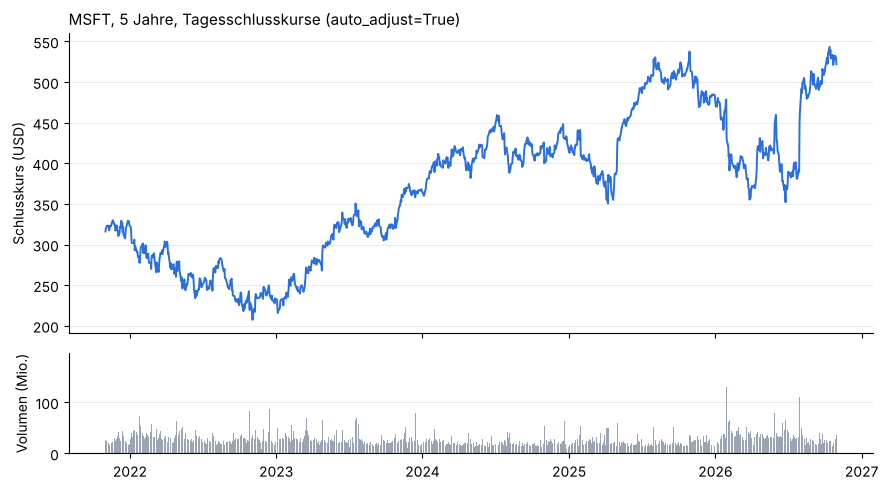

In [6]:
d = t.history(period="5y", interval="1d")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
a1.plot(d.index, d["Close"], color="#2a6fdb", lw=1.4); a1.set_ylabel("Schlusskurs (USD)")
a2.bar(d.index, d["Volume"] / 1e6, color="#9aa4b2", width=1.5); a2.set_ylabel("Volumen (Mio.)")
for a in (a1, a2):
    a.spines[["top", "right"]].set_visible(False); a.grid(axis="y", alpha=.25)
a1.set_title("MSFT, 5 Jahre, Tagesschlusskurse (auto_adjust=True)", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

## 3. Dividenden, Splits, Aktionen

In [7]:
run("Aktionen", "dividends", lambda: t.dividends.tail(5))
run("Aktionen", "splits", lambda: t.splits)
run("Aktionen", "actions", lambda: t.actions.tail(5))
run("Aktionen", "capital_gains (nur Fonds)", lambda: t.capital_gains)
run("Aktionen", "get_shares_full (Aktienanzahl)", lambda: t.get_shares_full(start="2024-01-01"))

[ok    ] dividends                              Größe=5       0.41s 


Date
2025-08-21 09:30:00-04:00    0.83
2025-11-20 09:30:00-05:00    0.91
2026-02-19 09:30:00-05:00    0.91
2026-05-21 09:30:00-04:00    0.91
2026-08-20 09:30:00-04:00    0.91
Name: Dividends, dtype: float64

[ok    ] splits                                 Größe=9       0.00s 


Date
1987-09-21 09:30:00-04:00    2.0
1990-04-16 09:30:00-04:00    2.0
1991-06-27 09:30:00-04:00    1.5
1992-06-15 09:30:00-04:00    1.5
1994-05-23 09:30:00-04:00    2.0
Name: Stock Splits, dtype: float64

[ok    ] actions                                Größe=5       0.00s 


,Dividends,Stock Splits
Date,,
2025-08-21 00:00:00-04:00,0.83,0.0
2025-11-20 00:00:00-05:00,0.91,0.0
2026-02-19 00:00:00-05:00,0.91,0.0
2026-05-21 00:00:00-04:00,0.91,0.0
2026-08-20 00:00:00-04:00,0.91,0.0


[leer  ] capital_gains (nur Fonds)              Größe=0       0.00s 
[ok    ] get_shares_full (Aktienanzahl)         Größe=356     0.16s 


2024-01-04 00:00:00-05:00    7432260096
2024-01-05 00:00:00-05:00    7486799872
2024-01-05 00:00:00-05:00    7432260096
2024-01-06 00:00:00-05:00    7432260096
2024-01-09 00:00:00-05:00    7432260096
dtype: int64

2024-01-04 00:00:00-05:00    7432260096
2024-01-05 00:00:00-05:00    7486799872
2024-01-05 00:00:00-05:00    7432260096
2024-01-06 00:00:00-05:00    7432260096
2024-01-09 00:00:00-05:00    7432260096
                                ...    
2026-02-04 00:00:00-05:00    7432377656
2026-05-01 00:00:00-04:00    7428434704
2026-07-31 00:00:00-04:00    7425545491
2026-10-30 00:00:00-04:00    7426194552
2026-10-31 00:00:00-04:00    7426194552
Length: 356, dtype: int64

## 4. Finanzberichte

Jahres-, Quartals- und TTM-Sicht für GuV, Bilanz und Cashflow. Yahoo liefert über diesen Weg typischerweise nur
**4–5 Jahres- und 5–7 Quartalsperioden**. Das ist für eine lange Bewertungshistorie zu wenig.

In [8]:
fin = {}
for label, attr in [("income_stmt", "income_stmt"), ("quarterly_income_stmt", "quarterly_income_stmt"), ("ttm_income_stmt", "ttm_income_stmt"),
                    ("balance_sheet", "balance_sheet"), ("quarterly_balance_sheet", "quarterly_balance_sheet"),
                    ("cashflow", "cashflow"), ("quarterly_cashflow", "quarterly_cashflow"), ("ttm_cashflow", "ttm_cashflow")]:
    fin[label] = run("Finanzen", label, lambda a=attr: getattr(t, a), show=False)
inc = fin["income_stmt"]
display(inc.loc[[r for r in ["Total Revenue", "Gross Profit", "Operating Income", "Net Income", "Diluted EPS"] if r in inc.index]])

[ok    ] income_stmt                            Größe=47      0.28s 


[ok    ] quarterly_income_stmt                  Größe=47      0.28s 


[ok    ] ttm_income_stmt                        Größe=47      0.29s 


[ok    ] balance_sheet                          Größe=79      0.35s 


[ok    ] quarterly_balance_sheet                Größe=79      0.30s 


[ok    ] cashflow                               Größe=59      0.39s 


[ok    ] quarterly_cashflow                     Größe=60      0.23s 


[ok    ] ttm_cashflow                           Größe=56      0.21s 


,2026-06-30,2025-06-30,2024-06-30,2023-06-30
Total Revenue,3.318390e+11,2.817240e+11,2.451220e+11,2.119150e+11
Gross Profit,2.254650e+11,1.938930e+11,1.710080e+11,1.460520e+11
Operating Income,1.552370e+11,1.285280e+11,1.094330e+11,8.852300e+10
Net Income,1.337490e+11,1.018320e+11,8.813600e+10,7.236100e+10
Diluted EPS,1.795000e+01,1.364000e+01,1.180000e+01,9.680000e+00


In [9]:
run("Finanzen", "get_income_stmt(freq='quarterly', pretty=True)", lambda: t.get_income_stmt(freq="quarterly", pretty=True), rows=4)

[ok    ] get_income_stmt(freq='quarterly', pretty=True) Größe=47      0.00s 


,2026-09-30,2026-06-30,2026-03-31,2025-12-31,2025-09-30
Tax Effect Of Unusual Items,-2.360000e+07,5.514149e+08,2.813900e+08,6.520000e+07,1.882070e+08
Tax Rate For Calcs,2.000000e-01,1.880040e-01,1.900000e-01,2.000000e-01,1.910730e-01
Normalized EBITDA,5.868500e+10,5.297500e+10,4.880400e+10,5.785400e+10,4.216100e+10
Total Unusual Items,-1.180000e+08,2.933000e+09,1.481000e+09,3.260000e+08,9.850000e+08


,2026-09-30,2026-06-30,2026-03-31,2025-12-31,2025-09-30
Tax Effect Of Unusual Items,-2.360000e+07,5.514149e+08,2.813900e+08,6.520000e+07,1.882070e+08
Tax Rate For Calcs,2.000000e-01,1.880040e-01,1.900000e-01,2.000000e-01,1.910730e-01
Normalized EBITDA,5.868500e+10,5.297500e+10,4.880400e+10,5.785400e+10,4.216100e+10
Total Unusual Items,-1.180000e+08,2.933000e+09,1.481000e+09,3.260000e+08,9.850000e+08
Total Unusual Items Excluding Goodwill,-1.180000e+08,2.933000e+09,1.481000e+09,3.260000e+08,9.850000e+08
Net Income From Continuing Operation Net Minority Interest,3.662900e+10,3.576600e+10,3.177800e+10,3.845800e+10,2.774700e+10
Reconciled Depreciation,1.174400e+10,1.102200e+10,1.016700e+10,9.198000e+09,8.147000e+09
Reconciled Cost Of Revenue,2.972000e+10,2.952500e+10,2.682800e+10,2.597800e+10,2.404300e+10
EBITDA,5.856700e+10,5.590800e+10,5.028500e+10,5.818000e+10,4.314600e+10
EBIT,4.682300e+10,4.488600e+10,4.011800e+10,4.898200e+10,3.499900e+10


**Plausibilitätsprüfungen** an den Berichten: Bilanzgleichung, Free Cashflow, Bruttogewinn.

In [10]:
bs, cf = fin["balance_sheet"], fin["cashflow"]
chk = pd.DataFrame({
    "Bilanz: Aktiva - Passiva - EK": bs.loc["Total Assets"] - bs.loc["Total Liabilities Net Minority Interest"] - bs.loc["Stockholders Equity"],
    "FCF - (OCF + Capex)": cf.loc["Free Cash Flow"] - (cf.loc["Operating Cash Flow"] + cf.loc["Capital Expenditure"]),
    "Bruttogewinn - (Umsatz - Umsatzkosten)": inc.loc["Gross Profit"] - (inc.loc["Total Revenue"] - inc.loc["Cost Of Revenue"]),
})
display(chk.T)
print("Alle Abweichungen 0 bedeutet: Berichte sind intern konsistent.")

,2022-06-30,2023-06-30,2024-06-30,2025-06-30,2026-06-30
Bilanz: Aktiva - Passiva - EK,NaN,0.0,0.0,0.0,0.0
FCF - (OCF + Capex),NaN,0.0,0.0,0.0,0.0
Bruttogewinn - (Umsatz - Umsatzkosten),NaN,0.0,0.0,0.0,0.0


Alle Abweichungen 0 bedeutet: Berichte sind intern konsistent.


## 5. Ergebnistermine und Gewinn

In [11]:
run("Earnings", "earnings_dates", lambda: t.earnings_dates)
run("Earnings", "earnings_history", lambda: t.earnings_history)
run("Earnings", "calendar", lambda: t.calendar, rows=8)

[ok    ] earnings_dates                         Größe=25      0.70s 


,EPS Estimate,Reported EPS,Surprise(%)
Earnings Date,,,
2027-01-27 15:00:00-05:00,4.86,NaN,NaN
2026-10-28 16:00:00-04:00,4.72,4.89,3.59
2026-07-29 16:00:00-04:00,4.24,4.74,11.81
2026-04-29 16:00:00-04:00,4.07,4.27,4.85
2026-01-28 16:00:00-05:00,3.92,4.14,5.69


[ok    ] earnings_history                       Größe=4       0.48s 


,epsActual,epsEstimate,epsDifference,surprisePercent
quarter,,,,
2025-12-31,4.14,3.91702,0.22,0.0569
2026-03-31,4.27,4.07243,0.20,0.0485
2026-06-30,4.74,4.23939,0.50,0.1181
2026-09-30,4.89,4.72072,0.17,0.0359


[ok    ] calendar                               Größe=9       0.15s 


Dividend Date         2026-12-10
Ex-Dividend Date      2026-11-19
Earnings Date       [2027-01-27]
Earnings High            4.97073
Earnings Low                4.82
Earnings Average         4.86024
Revenue High         97868000000
Revenue Low          95582000000
dtype: object

{'Dividend Date': datetime.date(2026, 12, 10),
 'Ex-Dividend Date': datetime.date(2026, 11, 19),
 'Earnings Date': [datetime.date(2027, 1, 27)],
 'Earnings High': 4.97073,
 'Earnings Low': 4.82,
 'Earnings Average': 4.86024,
 'Revenue High': 97868000000,
 'Revenue Low': 95582000000,
 'Revenue Average': 96627860740}

## 6. Analysten

In [12]:
run("Analysten", "analyst_price_targets", lambda: t.analyst_price_targets)
run("Analysten", "recommendations", lambda: t.recommendations)
run("Analysten", "recommendations_summary", lambda: t.recommendations_summary)
run("Analysten", "upgrades_downgrades", lambda: t.upgrades_downgrades)
run("Analysten", "earnings_estimate", lambda: t.earnings_estimate)
run("Analysten", "revenue_estimate", lambda: t.revenue_estimate)
run("Analysten", "eps_trend", lambda: t.eps_trend)
run("Analysten", "eps_revisions", lambda: t.eps_revisions)
run("Analysten", "growth_estimates", lambda: t.growth_estimates)

[ok    ] analyst_price_targets                  Größe=5       0.16s 


current    521.9100
high       870.0000
low        440.0000
mean       629.6884
median     630.0000
dtype: float64

[ok    ] recommendations                        Größe=4       0.17s 


,period,strongBuy,buy,hold,sell,strongSell
0,0m,12,39,5,0,0
1,-1m,14,39,2,0,0
2,-2m,14,38,3,0,0
3,-3m,14,40,3,0,0


[ok    ] recommendations_summary                Größe=4       0.00s 


...

[ok    ] eps_revisions                          Größe=4       0.00s 


,upLast7days,upLast30days,downLast30days,downLast7Days,currency
period,,,,,
0q,2,2,3,1,USD
+1q,2,3,1,1,USD
0y,4,5,0,0,USD
+1y,3,4,2,1,USD


[ok    ] growth_estimates                       Größe=5       0.21s 


,stockTrend,indexTrend
period,,
0q,0.1740,0.2573
+1q,0.1593,0.2739
0y,0.1588,0.3308
+1y,0.2057,0.1655
LTG,NaN,0.1220


,stockTrend,indexTrend
period,,
0q,0.1740,0.2573
+1q,0.1593,0.2739
0y,0.1588,0.3308
+1y,0.2057,0.1655
LTG,NaN,0.1220


## 7. Eigentümer und Insider

In [13]:
run("Eigentümer", "major_holders", lambda: t.major_holders)
run("Eigentümer", "institutional_holders", lambda: t.institutional_holders)
run("Eigentümer", "mutualfund_holders", lambda: t.mutualfund_holders)
run("Eigentümer", "insider_transactions", lambda: t.insider_transactions)
run("Eigentümer", "insider_purchases", lambda: t.insider_purchases)
run("Eigentümer", "insider_roster_holders", lambda: t.insider_roster_holders)

[ok    ] major_holders                          Größe=4       0.16s 


Breakdown,Value
insidersPercentHeld,0.00079
institutionsPercentHeld,0.75798
institutionsFloatPercentHeld,0.75858
institutionsCount,8181.00000


[ok    ] institutional_holders                  Größe=10      0.00s 


,Date Reported,Holder,pctHeld,Shares,Value,pctChange
0,2026-06-30,Blackrock Inc.,0.0818,607367113,316990953634,0.0237
1,2026-06-30,Vanguard Capital Management LLC,0.0653,485192007,253226547343,0.0055
2,2026-06-30,State Street Corporation,0.0425,315653206,164742556266,0.0292
3,2026-06-30,"Geode Capital Management, LLC",0.0255,189632090,98970878999,0.0060
4,2026-06-30,"FMR, LLC",0.0250,185960066,97054413052,-0.0224


[ok    ] mutualfund_holders                     Größe=10      0.00s 


...

[ok    ] insider_purchases                      Größe=7       0.00s 


,Insider Purchases Last 6m,Shares,Trans
0,Purchases,513644.0,16
1,Sales,249649.0,10
2,Net Shares Purchased (Sold),263995.0,26
3,Total Insider Shares Held,5866694.0,<NA>
4,% Net Shares Purchased (Sold),0.047,<NA>


[ok    ] insider_roster_holders                 Größe=10      0.00s 


,Name,Position,URL,Most Recent Transaction,Latest Transaction Date,Shares Owned Directly,Position Direct Date
0,ALTHOFF JUDSON,Officer,,Stock Award(Grant),2026-08-31,112091,2026-08-31
1,COLEMAN AMY,Officer,,Sale,2026-05-14,45914,2026-05-14
2,HOGAN KATHLEEN T,Officer,,Sale,2026-03-06,137933,2026-03-06
3,HOOD AMY E,Chief Financial Officer,,Sale,2026-10-13,555396,2026-10-13
4,JOLLA ALICE L,Officer,,Stock Award(Grant),2026-08-31,81241,2026-08-31


,Name,Position,URL,Most Recent Transaction,Latest Transaction Date,Shares Owned Directly,Position Direct Date
0,ALTHOFF JUDSON,Officer,,Stock Award(Grant),2026-08-31,112091,2026-08-31
1,COLEMAN AMY,Officer,,Sale,2026-05-14,45914,2026-05-14
2,HOGAN KATHLEEN T,Officer,,Sale,2026-03-06,137933,2026-03-06
3,HOOD AMY E,Chief Financial Officer,,Sale,2026-10-13,555396,2026-10-13
4,JOLLA ALICE L,Officer,,Stock Award(Grant),2026-08-31,81241,2026-08-31
5,NADELLA SATYA,Chief Executive Officer,,Sale,2026-09-01,918227,2026-09-01
6,NUMOTO TAKESHI,Officer,,Stock Award(Grant),2026-08-31,47843,2026-08-31
7,SMITH BRADFORD LEE,Officer,,Stock Gift,2026-09-09,444716,2026-09-09
8,STANTON JOHN W.,Director,,Stock Award(Grant),2026-09-04,87801,2026-09-04
9,YOUNG CHRISTOPHER DAVID,Officer,,Sale,2024-11-12,104866,2024-11-12


## 8. Sonstiges: Nachhaltigkeit, Nachrichten, Filings, Optionen

In [14]:
run("Sonstiges", "sustainability", lambda: t.sustainability)
run("Sonstiges", "news", lambda: t.news)
run("Sonstiges", "sec_filings", lambda: t.sec_filings)
opts = run("Sonstiges", "options (Verfallstermine)", lambda: t.options)
if opts: run("Sonstiges", "option_chain(erster Termin).calls", lambda: t.option_chain(opts[0]).calls, rows=3)

HTTP Error 404: Not Found{"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"No fundamentals data found for symbol: MSFT"}}}


[leer  ] sustainability                         Größe=0       0.57s 


[leer  ] news                                   Größe=0       0.54s 
[ok    ] sec_filings                            Größe=87      0.17s 


[{'date': datetime.date(2026, 10, 28),
  'epochDate': 1793145600,
  'type': '8-K',
  'title': 'Corporate Changes & Voting Matters',
  'edgarUrl': 'https://finance.yahoo.com/sec-filing/MSFT/0001193125-26-436149_789019',
  'exhibits': {'8-K': 'https://cdn.yahoofinance.com/prod/sec-filings/0000789019/000119312526436149/msft-20261028.htm',
   'EX-23.1': 'https://cdn.yahoofinance.com/prod/sec-filings/0000789019/000119312526436149/msft-ex23_1.htm',
   'EX-99.1': 'https://cdn.yahoofinance.com/prod/sec-filings/0000789019/000119312526436149/msft-ex99_1.htm'},
  'maxAge': 1},
 {'date': datetime.date(2026, 10, 27),
  'epochDate': 1793059200,
  'type': 'PX14A6G',
  'title': 'Notice of exempt solicitation',
  'edgarUrl': 'https://finance.yahoo.com/sec-filing/MSFT/0001214659-26-013276_789019',
  'exhibits': {'PX14A6G': 'https://cdn.yahoofinance.com/prod/sec-filings/0000789019/000121465926013276/y1027263px14a6g.htm'},
  'maxAge': 1},
 {'date': datetime.date(2026, 10, 26),
  'epochDate': 1792972800,
 

[ok    ] options (Verfallstermine)              Größe=19      0.17s 
('2026-11-02', '2026-11-04', '2026-11-06', '2026-11-13', '2026-11-20', '2026-11-27', '2026-12-04', '2026-12-18', '2027-01-15', '2027-02-19', '2027-03-19', '2027-04-16', '2027-06-17', '2027-09-17', '2027-12-17', '2028-01-21', '2028-06-16', '2028-12-15', '2029-01-19')
[ok    ] option_chain(erster Termin).calls      Größe=64      0.18s 


,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,...,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency
0,MSFT261102C00420000,2026-10-26 18:27:21+00:00,420.0,112.65,100.7,103.75,...,2,2,1.141606,True,REGULAR,USD
1,MSFT261102C00425000,2026-10-27 13:42:55+00:00,425.0,106.43,95.7,98.75,...,2,2,1.087895,True,REGULAR,USD
2,MSFT261102C00430000,2026-10-30 19:52:19+00:00,430.0,93.52,90.7,93.75,...,1,2,1.034185,True,REGULAR,USD


## 9. Modul-Funktionen: Suche, Sektoren, Märkte, Screener

In [15]:
run("Modul", "yf.Search('Microsoft').quotes", lambda: yf.Search("Microsoft", max_results=5).quotes, rows=3)
run("Modul", "yf.Lookup('Microsoft').stock", lambda: yf.Lookup("Microsoft").stock, rows=3)
run("Modul", "yf.Sector('technology').top_companies", lambda: yf.Sector("technology").top_companies, rows=3)
run("Modul", "yf.Industry('software-infrastructure').top_companies", lambda: yf.Industry("software-infrastructure").top_companies, rows=3)
run("Modul", "yf.Market('US').status", lambda: yf.Market("US").status, rows=4)
run("Modul", "yf.screen('day_gainers')", lambda: yf.screen("day_gainers", count=5)["quotes"], show=False)

[ok    ] yf.Search('Microsoft').quotes          Größe=5       0.31s 


[{'exchange': 'NMS',
  'shortname': 'Microsoft Corporation',
  'quoteType': 'EQUITY',
  'symbol': 'MSFT',
  'index': 'quotes',
  'score': 541880.0,
  'typeDisp': 'Equity',
  'longname': 'Microsoft Corporation',
  'exchDisp': 'NASDAQ',
  'sector': 'Technology',
  'sectorDisp': 'Technology',
  'industry': 'Software—Infrastructure',
  'industryDisp': 'Software—Infrastructure',
  'dispSecIndFlag': True,
  'isYahooFinance': True},
 {'exchange': 'CME',
  'shortname': 'Microsoft Corp Stock Futures,De',
  'quoteType': 'FUTURE',
  'symbol': 'SMSFT=F',
  'index': 'quotes',
  'score': 30054.0,
  'typeDisp': 'Futures',
  'longname': 'Microsoft Corp Single Stock futures',
  'exchDisp': 'Chicago Mercantile Exchange',
  'isYahooFinance': True},
 {'exchange': 'CME',
  'shortname': 'Micro Microsoft Corp Stock Futu',
  'quoteType': 'FUTURE',
  'symbol': 'XMSFT=F',
  'index': 'quotes',
  'score': 30025.0,
  'typeDisp': 'Futures',
  'exchDisp': 'Chicago Mercantile Exchange',
  'isYahooFinance': True}]

[ok    ] yf.Lookup('Microsoft').stock           Größe=25      0.19s 


,exchange,fulldayChange,fulldayChangePercent,fulldayPrice,industryLink,industryName,quoteType,rank,regularMarketChange,regularMarketPercentChange,regularMarketPrice,shortName
symbol,,,,,,,,,,,,
MSFT,NMS,-7.148010,-1.348325,521.909973,https://finance.yahoo.com/sector/tec...,Technology,equity,541880,-8.230040,-1.552430,521.909973,Microsoft Corporation
MSFT.TO,TOR,-0.590000,-1.597185,36.349998,https://finance.yahoo.com/sector/tec...,Technology,equity,20615,-0.590000,-1.597185,36.349998,MICROSOFT CDR (CAD HEDGED)
MSF.DE,GER,-1.849976,-0.393570,468.200012,https://finance.yahoo.com/sector/tec...,Technology,equity,20240,-1.849976,-0.393570,468.200012,MICROSOFT CORP. R


[ok    ] yf.Sector('technology').top_companies  Größe=50      0.20s 


...

,name,rating,market weight
symbol,,,
MSFT,Microsoft Corporation,Strong Buy,0.620111
PLTR,Palantir Technologies Inc.,Buy,0.070786
ORCL,Oracle Corporation,Buy,0.063378


[ok    ] yf.Market('US').status                 Größe=10      0.35s 


id                          us
name              U.S. markets
status                  closed
yfit_market_id       us_market
dtype: object

[ok    ] yf.screen('day_gainers')               Größe=5       0.19s 


[{'language': 'en-US',
  'region': 'US',
  'quoteType': 'EQUITY',
  'typeDisp': 'Equity',
  'quoteSourceName': 'Nasdaq Real Time Price',
  'triggerable': False,
  'customPriceAlertConfidence': 'LOW',
  'lastClosePriceToNNWCPerShare': 368.54409634064206,
  'currency': 'USD',
  'financialCurrency': 'USD',
  'shortName': 'CareDx, Inc.',
  'fulldayPrice': 87.41,
  'fulldayChange': 16.170006,
  'fulldayChangePercent': 22.60907,
  'ask': 60.27,
  'bid': 33.74,
  'marketCap': 4592764928,
  'postMarketChangePercent': 0.3203281,
  'postMarketTime': 1793397213,
  'postMarketPrice': 87.69,
  'postMarketChange': 0.27999878,
  'regularMarketChange': 15.89,
  'regularMarketTime': 1793390401,
  'regularMarketPrice': 87.41,
  'regularMarketDayHigh': 90.87,
  'regularMarketDayRange': '81.22 - 90.87',
  'regularMarketDayLow': 81.22,
  'regularMarketVolume': 3552531,
  'regularMarketPreviousClose': 71.52,
  'bidSize': 2,
  'askSize': 2,
  'market': 'us_market',
  'messageBoardId': 'finmb_9985914',
  'ful

## 10. Zusammenfassung: Welche Funktionen liefern Daten?

Die Tabelle fasst alle Aufrufe oben zusammen. `leer` heißt: Aufruf ging durch, Yahoo hat aber nichts geliefert
(bei Microsoft z. B. `capital_gains`, das nur für Fonds gilt). `fehler` ist ein Ausnahmefall im Aufruf (Fehlerklasse steht daneben).

In [16]:
log = pd.DataFrame(LOG)
display(log.groupby(["Bereich", "Status"]).size().unstack(fill_value=0))
print("Gesamt:", len(log), "Aufrufe | ok:", (log.Status == "ok").sum(), "| leer:", (log.Status == "leer").sum(), "| fehler:", (log.Status == "fehler").sum())
display(log[log.Status != "ok"][["Bereich", "Funktion", "Status", "Größe", "Fehler"]])

Status,leer,ok
Bereich,,
Aktionen,1,4
Analysten,0,9
Earnings,0,3
Eigentümer,0,6
Finanzen,0,9
Kurse,0,11
Modul,0,6
Sonstiges,2,3
Stammdaten,1,3


Gesamt: 58 Aufrufe | ok: 54 | leer: 4 | fehler: 0


,Bereich,Funktion,Status,Größe,Fehler
2,Stammdaten,get_isin,leer,0,
18,Aktionen,capital_gains (nur Fonds),leer,0,
47,Sonstiges,sustainability,leer,0,
48,Sonstiges,news,leer,0,


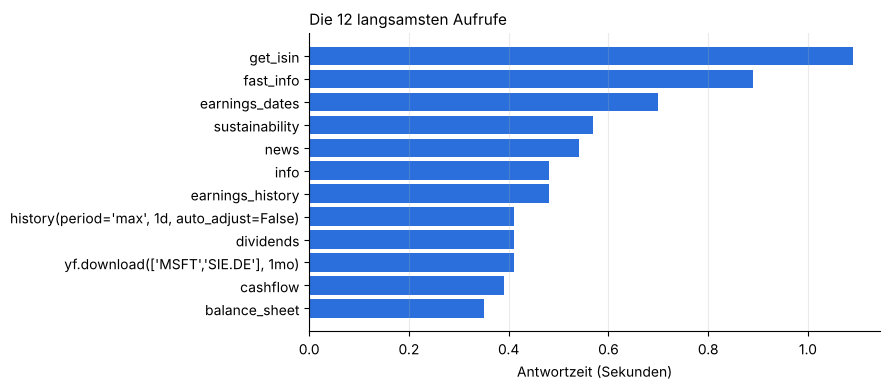

In [17]:
top = log.sort_values("Sekunden", ascending=False).head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(top["Funktion"].str.slice(0, 45), top["Sekunden"], color="#2a6fdb")
ax.set_xlabel("Antwortzeit (Sekunden)"); ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=.25)
ax.set_title("Die 12 langsamsten Aufrufe", loc="left", fontsize=11)
plt.tight_layout(); plt.show()